In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import pandas as pd
import psycopg2

conn = psycopg2.connect(
    host="localhost", port=5432, dbname="pro2d_db", user="postgres", password="postgres"
)

df = pd.read_sql("SELECT * FROM events", conn)
conn.close()

print("=== Spalten im DataFrame ===")
print(df.columns.tolist())
print(f"\nZeilen: {len(df)}, Spalten: {len(df.columns)}")

/var/folders/7x/4_7qkdl52m1f6f0kqw0hc6yw0000gn/T/ipykernel_14442/2819099016.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("SELECT * FROM events", conn)


=== Spalten im DataFrame ===
['Datum', 'Prio', 'Msr', 'Ort', 'Objekt', 'Meldung', 'Zustand', 'Benutzer', 'evtID', 'evtTyp']

Zeilen: 1054556, Spalten: 10


In [2]:
df["Benutzer"] = df["Benutzer"].replace("Vinzenzo Signorelli", "Vincenzo Signorelli")
df["Datum"] = pd.to_datetime(df["Datum"])

user_list = df["Benutzer"].fillna("NaN").value_counts().index.tolist()
PALETTE = [
    "#2563EB",
    "#DC2626",
    "#16A34A",
    "#F59E0B",
    "#8B5CF6",
    "#EC4899",
    "#0891B2",
    "#EA580C",
    "#4B5563",
    "#6D28D9",
    "#059669",
    "#D97706",
    "#7C3AED",
    "#BE185D",
    "#0D9488",
]
user_colors = {b: PALETTE[i % len(PALETTE)] for i, b in enumerate(user_list)}

/var/folders/7x/4_7qkdl52m1f6f0kqw0hc6yw0000gn/T/ipykernel_14442/115914679.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_yticklabels(
/var/folders/7x/4_7qkdl52m1f6f0kqw0hc6yw0000gn/T/ipykernel_14442/115914679.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_yticklabels(


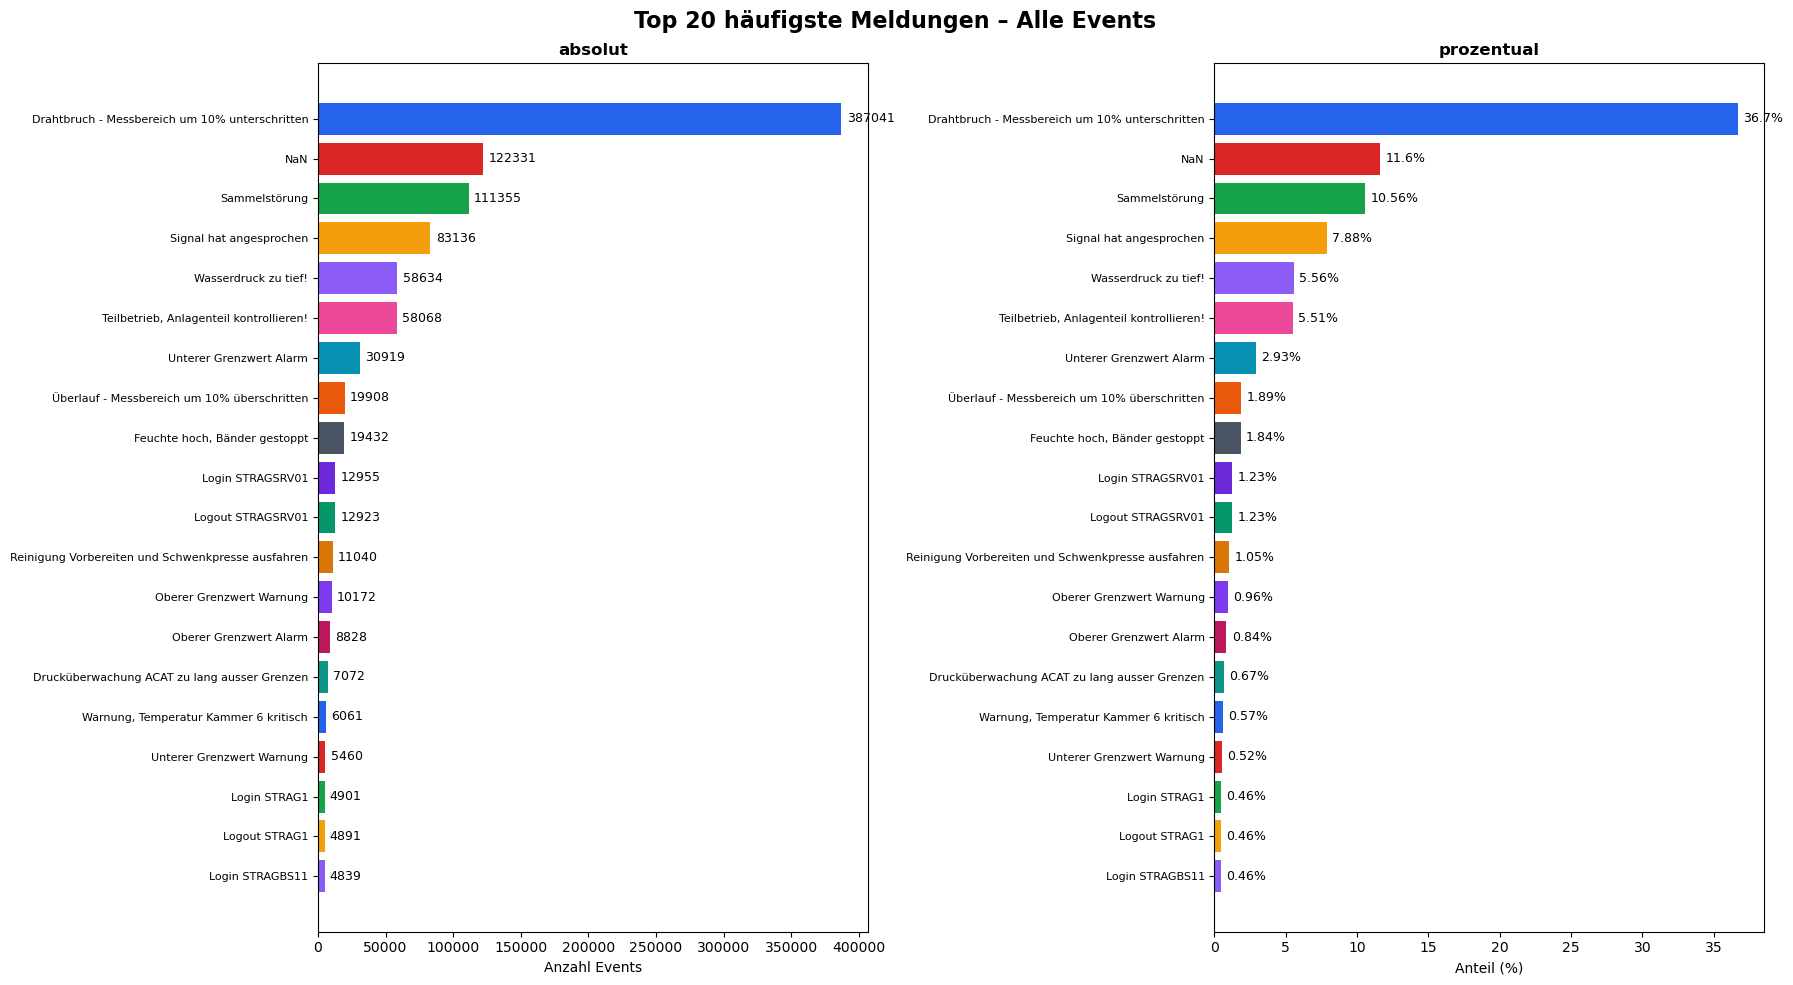

In [3]:
meld_counts = df["Meldung"].fillna("NaN").value_counts().head(20)
meld_colors = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(meld_counts.index)}

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

bars = axes[0].barh(
    meld_counts.index, meld_counts.values, color=[meld_colors[m] for m in meld_counts.index]
)
for bar, val in zip(bars, meld_counts.values, strict=False):
    axes[0].text(
        bar.get_width() + max(meld_counts.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va="center",
        fontsize=9,
    )
axes[0].set_xlabel("Anzahl Events")
axes[0].set_title("absolut", fontsize=12, fontweight="bold")
axes[0].set_yticklabels(
    [m[:50] + "..." if len(str(m)) > 50 else str(m) for m in meld_counts.index], fontsize=8
)
axes[0].invert_yaxis()

total = len(df)
meld_pct = (meld_counts / total * 100).round(2)
bars2 = axes[1].barh(
    meld_pct.index, meld_pct.values, color=[meld_colors[m] for m in meld_pct.index]
)
for bar, val in zip(bars2, meld_pct.values, strict=False):
    axes[1].text(
        bar.get_width() + max(meld_pct.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil (%)")
axes[1].set_title("prozentual", fontsize=12, fontweight="bold")
axes[1].set_yticklabels(
    [m[:50] + "..." if len(str(m)) > 50 else str(m) for m in meld_pct.index], fontsize=8
)
axes[1].invert_yaxis()

plt.suptitle("Top 20 häufigste Meldungen – Alle Events", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [4]:
print("=== MSR-Spalte Übersicht ===")
print(f"Anzahl unique MSR: {df['Msr'].nunique(dropna=False)}")
print(f"NaN-Werte: {df['Msr'].isna().sum()}")
print(f"\nTop 20 häufigste MSR-Nummern:")
print(df["Msr"].value_counts(dropna=False).head(20).to_string())

draht = df[df["Meldung"].str.contains("Drahtbruch", case=False, na=False)].copy()
print(f"\n=== Drahtbruch-Events ===")
print(f"Anzahl Drahtbruch-Events: {len(draht)}")
print(f"Anteil an allen Events: {len(draht) / len(df) * 100:.1f}%")
print(f"Anzahl betroffene MSR-Nummern: {draht['Msr'].nunique(dropna=False)}")
print(f"\nDrahtbruch pro MSR:")
print(draht["Msr"].value_counts(dropna=False).to_string())

=== MSR-Spalte Übersicht ===
Anzahl unique MSR: 690
NaN-Werte: 52613

Top 20 häufigste MSR-Nummern:
Msr
MI-156       267534
P-007        100412
PRG-36        59746
LIA-181       57985
NaN           52613
TI-165        37944
MI-214        37226
QISA-428      35718
PRG-00        33551
LS-113        27487
PRG-23        25021
PRG-20        20492
PRG-01        16913
PSFM-143      12432
PRG-35        11032
TI-218         9799
P-008          8789
LSFM-141       8372
H-005B         7239
PARA-3007      5891

=== Drahtbruch-Events ===
Anzahl Drahtbruch-Events: 387041
Anteil an allen Events: 36.7%
Anzahl betroffene MSR-Nummern: 111

Drahtbruch pro MSR:
Msr
MI-156         264668
TI-165          37801
MI-214          37122
QISA-428        29316
LI-118           3497
MI-156b          2831
PIAC-131         1632
QIZA-159         1161
QIA-200           743
QIZA-201          550
QIZA-176a         536
LISA-103          432
FT-551            409
QIZA-176          407
TI-218            405
TIZA-164        

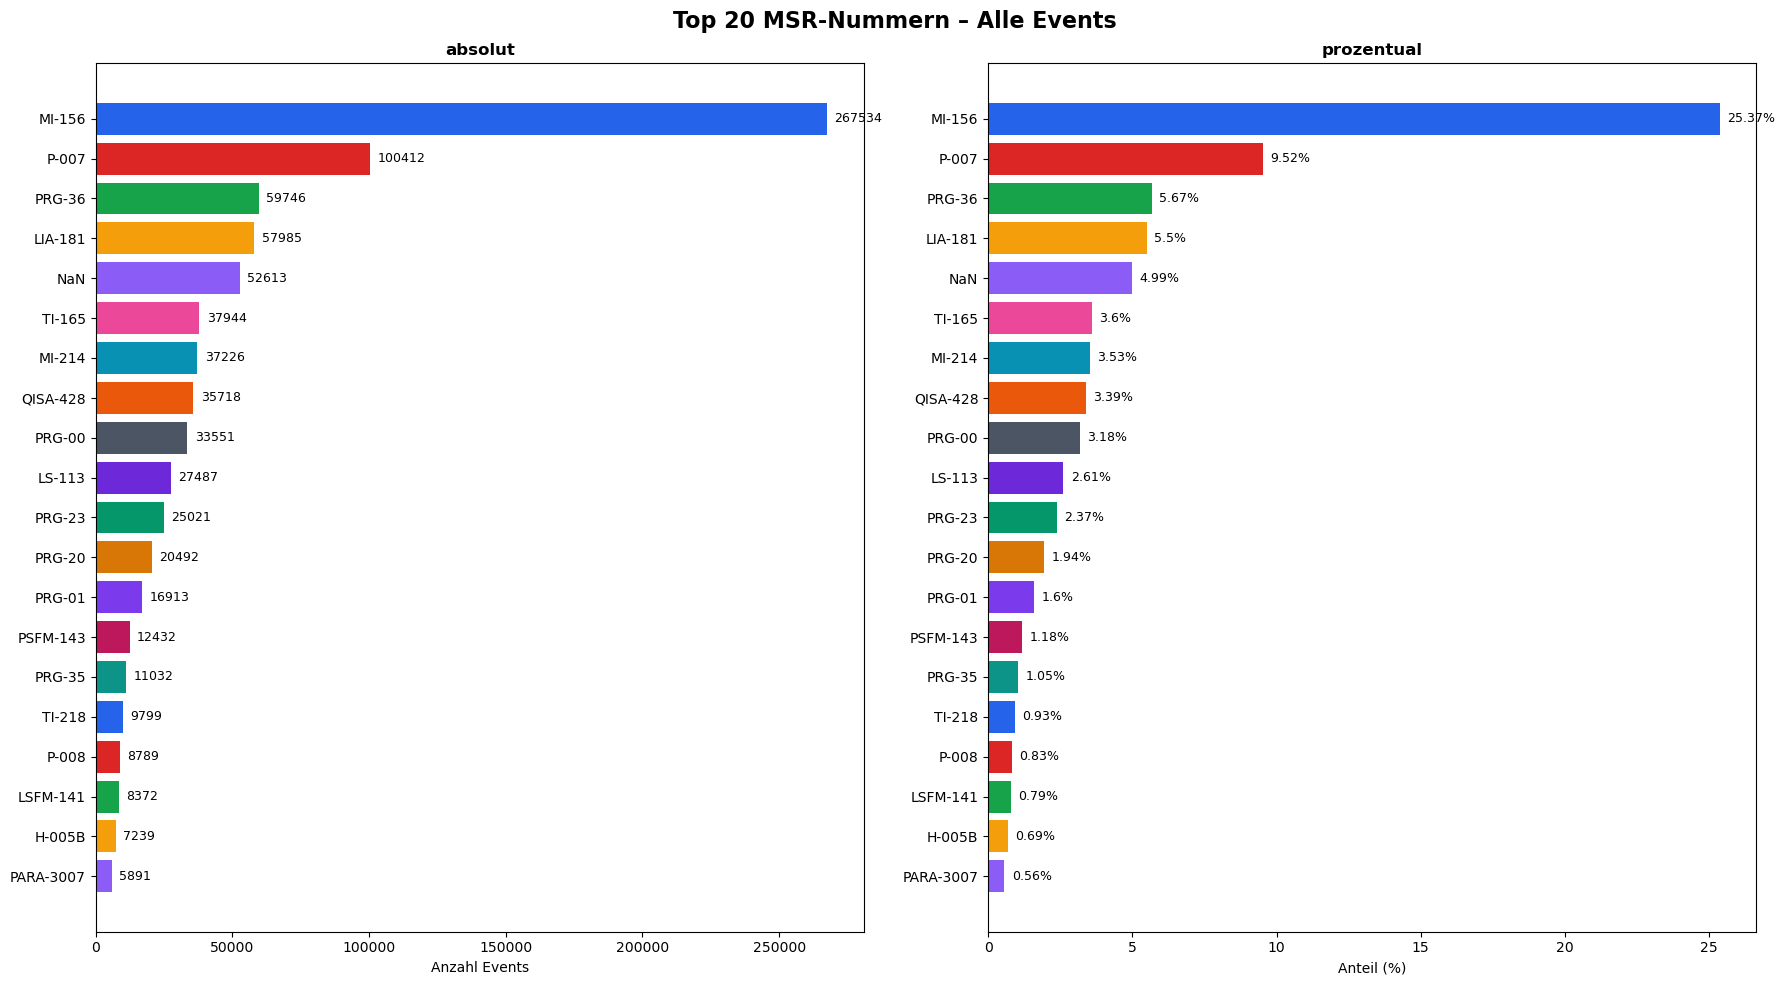

In [5]:
msr_counts_20 = df["Msr"].fillna("NaN").value_counts().head(20)
msr_colors_20 = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(msr_counts_20.index)}

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

bars = axes[0].barh(
    msr_counts_20.index, msr_counts_20.values, color=[msr_colors_20[m] for m in msr_counts_20.index]
)
for bar, val in zip(bars, msr_counts_20.values, strict=False):
    axes[0].text(
        bar.get_width() + max(msr_counts_20.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va="center",
        fontsize=9,
    )
axes[0].set_xlabel("Anzahl Events")
axes[0].set_title("absolut", fontsize=12, fontweight="bold")
axes[0].invert_yaxis()

msr_pct_20 = (msr_counts_20 / len(df) * 100).round(2)
bars2 = axes[1].barh(
    msr_pct_20.index, msr_pct_20.values, color=[msr_colors_20[m] for m in msr_pct_20.index]
)
for bar, val in zip(bars2, msr_pct_20.values, strict=False):
    axes[1].text(
        bar.get_width() + max(msr_pct_20.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil (%)")
axes[1].set_title("prozentual", fontsize=12, fontweight="bold")
axes[1].invert_yaxis()

plt.suptitle("Top 20 MSR-Nummern – Alle Events", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

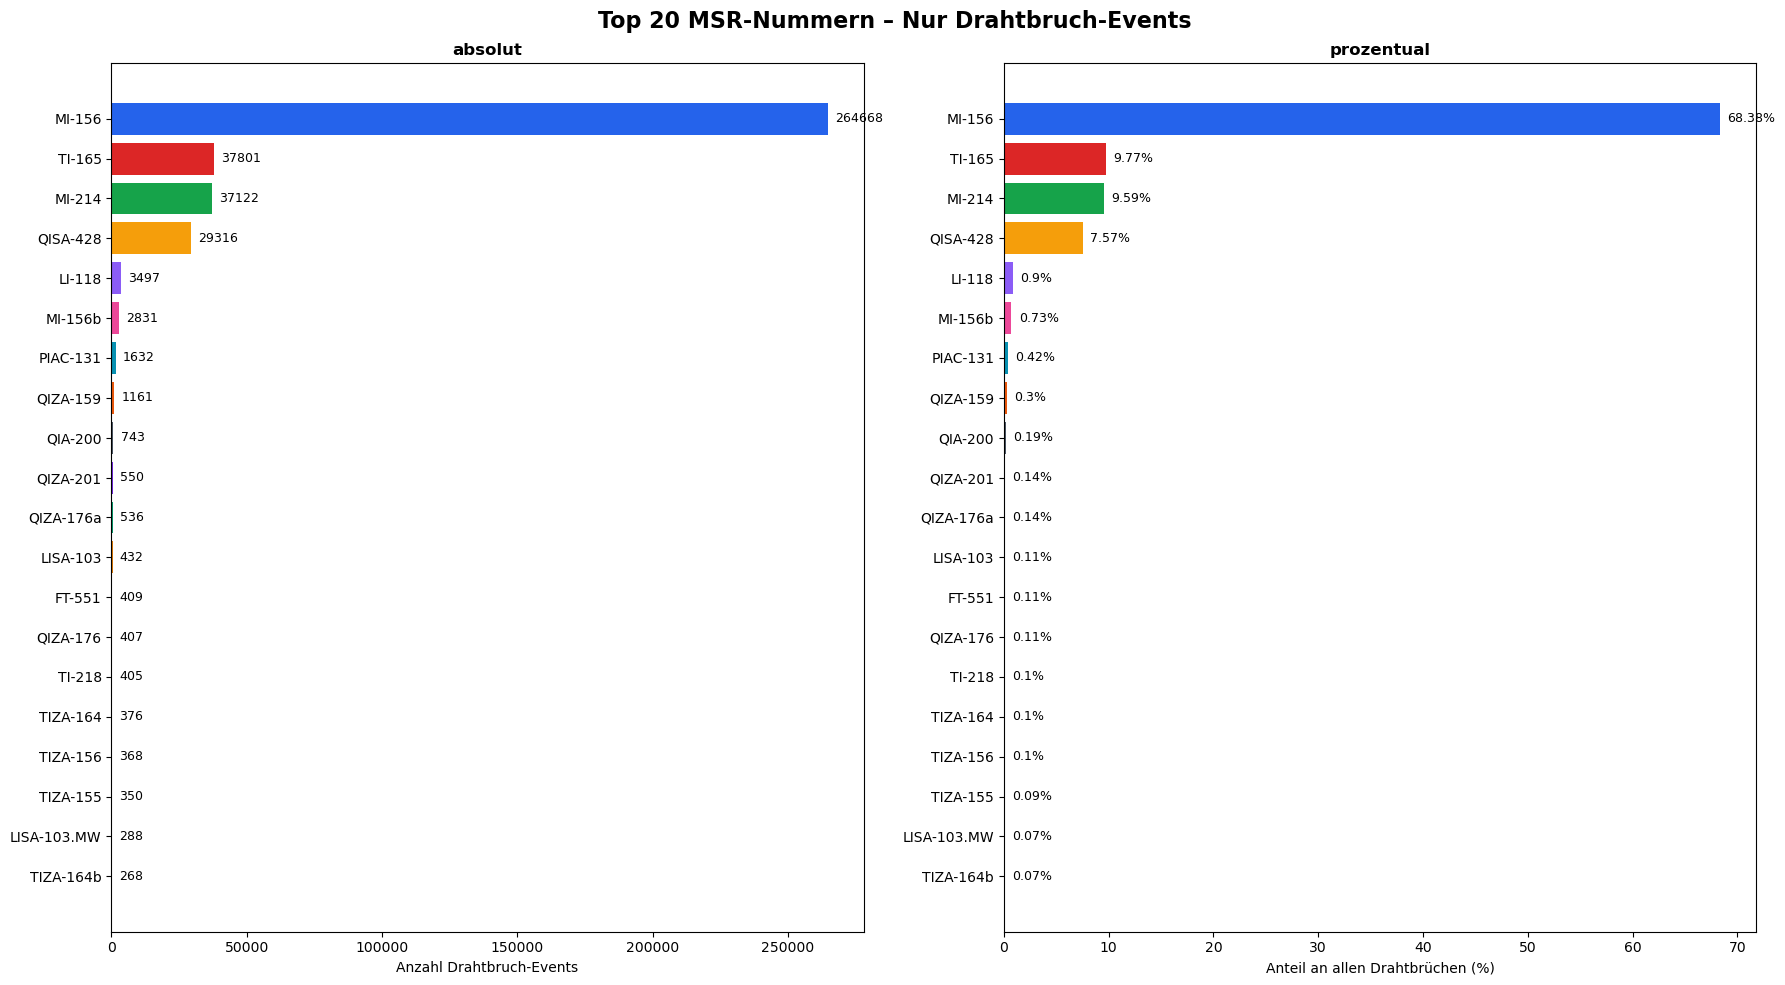

In [6]:
draht_msr = draht["Msr"].fillna("NaN").value_counts().head(20)
draht_msr_colors = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(draht_msr.index)}

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

bars = axes[0].barh(
    draht_msr.index, draht_msr.values, color=[draht_msr_colors[m] for m in draht_msr.index]
)
for bar, val in zip(bars, draht_msr.values, strict=False):
    axes[0].text(
        bar.get_width() + max(draht_msr.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va="center",
        fontsize=9,
    )
axes[0].set_xlabel("Anzahl Drahtbruch-Events")
axes[0].set_title("absolut", fontsize=12, fontweight="bold")
axes[0].invert_yaxis()

total_draht = len(draht)
draht_pct = (draht_msr / total_draht * 100).round(2)
bars2 = axes[1].barh(
    draht_pct.index, draht_pct.values, color=[draht_msr_colors[m] for m in draht_pct.index]
)
for bar, val in zip(bars2, draht_pct.values, strict=False):
    axes[1].text(
        bar.get_width() + max(draht_pct.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil an allen Drahtbrüchen (%)")
axes[1].set_title("prozentual", fontsize=12, fontweight="bold")
axes[1].invert_yaxis()

plt.suptitle("Top 20 MSR-Nummern – Nur Drahtbruch-Events", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
top4 = draht["Msr"].value_counts().head(4).index.tolist()
draht_top4 = draht[draht["Msr"].isin(top4)].copy()
draht_top4["Monat"] = draht_top4["Datum"].dt.to_period("M")
draht_top4["Stunde"] = draht_top4["Datum"].dt.hour
msr_colors = {msr: PALETTE[i] for i, msr in enumerate(top4)}

print(f"Top 4 MSR bei Drahtbruch: {top4}")
for msr in top4:
    cnt = len(draht_top4[draht_top4["Msr"] == msr])
    print(f"  {msr}: {cnt} Events ({cnt / len(draht) * 100:.1f}%)")

Top 4 MSR bei Drahtbruch: ['MI-156', 'TI-165', 'MI-214', 'QISA-428']
  MI-156: 264668 Events (68.4%)
  TI-165: 37801 Events (9.8%)
  MI-214: 37122 Events (9.6%)
  QISA-428: 29316 Events (7.6%)


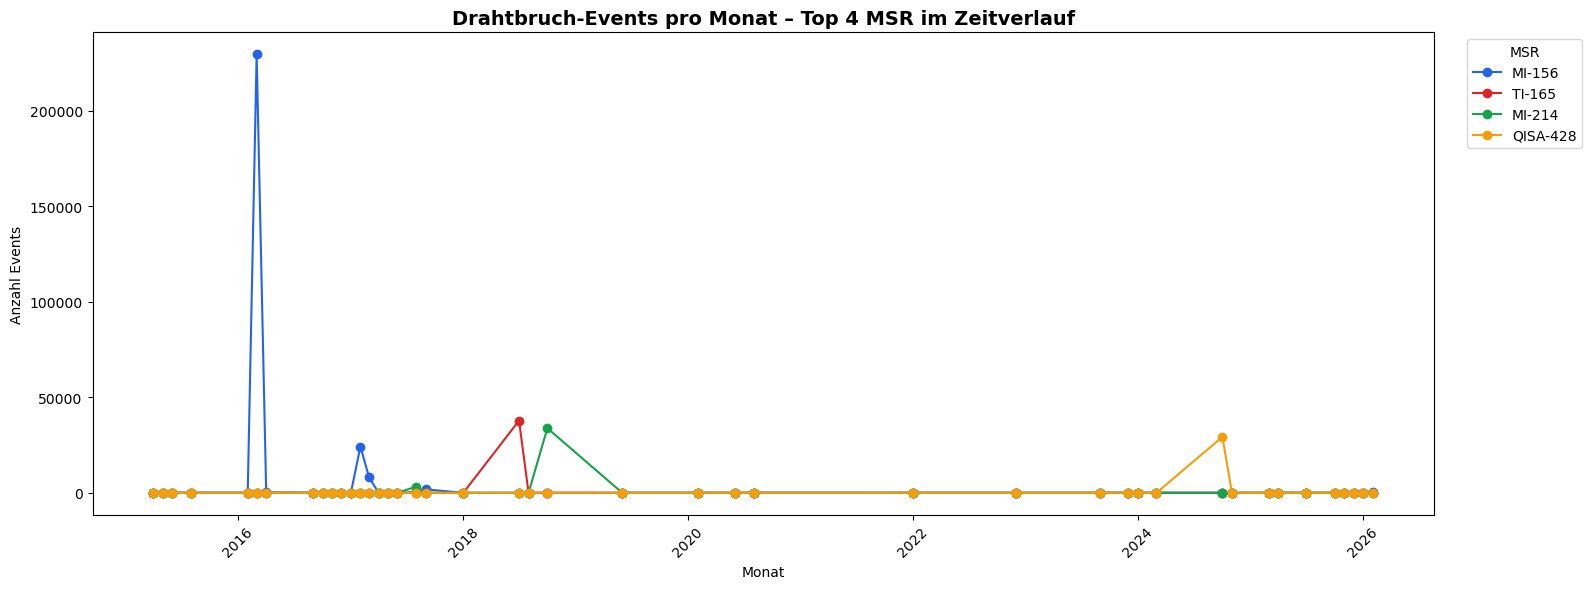

In [8]:
fig, ax = plt.subplots(figsize=(16, 6))
pivot = draht_top4.groupby(["Monat", "Msr"]).size().unstack(fill_value=0)
pivot.index = pivot.index.to_timestamp()
for msr in top4:
    if msr in pivot.columns:
        ax.plot(pivot.index, pivot[msr], marker="o", label=msr, color=msr_colors[msr])
ax.set_title(
    "Drahtbruch-Events pro Monat – Top 4 MSR im Zeitverlauf", fontsize=14, fontweight="bold"
)
ax.set_xlabel("Monat")
ax.set_ylabel("Anzahl Events")
ax.legend(title="MSR", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
draht_mi156 = draht[draht["Msr"] == "MI-156"].copy()
draht_mi156["Monat"] = draht_mi156["Datum"].dt.to_period("M")

monat_counts = draht_mi156.groupby("Monat").size().sort_values(ascending=False)
total_mi156 = len(draht_mi156)

print("=== MI-156 Drahtbruch – Top 10 Monate ===")
print(f"Total MI-156 Drahtbrüche: {total_mi156}")
print(f"\n{'Monat':<12} {'Anzahl':>10} {'Anteil':>10}")
print("=" * 35)
for monat, count in monat_counts.head(10).items():
    pct = count / total_mi156 * 100
    print(f"{str(monat):<12} {count:>10} {pct:>9.1f}%")

peak_monat = monat_counts.index[0]
peak_data = draht_mi156[draht_mi156["Monat"] == peak_monat]

print(f"\n=== Detail Peak-Monat: {peak_monat} ===")
print(f"Anzahl Events: {len(peak_data)}")
print(f"Anteil an allen MI-156 Drahtbrüchen: {len(peak_data) / total_mi156 * 100:.1f}%")
print(f"Anteil an allen Drahtbrüchen gesamt: {len(peak_data) / len(draht) * 100:.1f}%")
print(f"\nZeitraum: {peak_data['Datum'].min()} bis {peak_data['Datum'].max()}")
print(f"Anzahl Tage mit Events: {peak_data['Datum'].dt.date.nunique()}")
print(f"\nPro Tag:")
print(
    peak_data.groupby(peak_data["Datum"].dt.date)
    .size()
    .sort_values(ascending=False)
    .head(10)
    .to_string()
)
print(f"\nObjekte:")
print(peak_data["Objekt"].value_counts().head(10).to_string())
print(f"\nZustand:")
print(peak_data["Zustand"].value_counts(dropna=False).to_string())
print(f"\nBenutzer:")
print(peak_data["Benutzer"].value_counts(dropna=False).to_string())
print(f"\nPrio:")
print(peak_data["Prio"].value_counts(dropna=False).to_string())

=== MI-156 Drahtbruch – Top 10 Monate ===
Total MI-156 Drahtbrüche: 264668

Monat            Anzahl     Anteil
2016-03          229563      86.7%
2017-02           24211       9.1%
2017-03            8049       3.0%
2017-09            1802       0.7%
2017-08             393       0.1%
2026-02             360       0.1%
2016-04             185       0.1%
2016-09              35       0.0%
2025-04              10       0.0%
2020-08               8       0.0%

=== Detail Peak-Monat: 2016-03 ===
Anzahl Events: 229563
Anteil an allen MI-156 Drahtbrüchen: 86.7%
Anteil an allen Drahtbrüchen gesamt: 59.3%

Zeitraum: 2016-03-03 10:36:19.273000 bis 2016-03-30 10:14:25.890000
Anzahl Tage mit Events: 8

Pro Tag:
Datum
2016-03-04    119854
2016-03-05     89327
2016-03-03     19743
2016-03-29       511
2016-03-19       120
2016-03-18         4
2016-03-30         3
2016-03-07         1

Objekte:
Objekt
Feuchte Abluft    229563

Zustand:
Zustand
Freigabe       57399
Geht           57393
Quittierung   

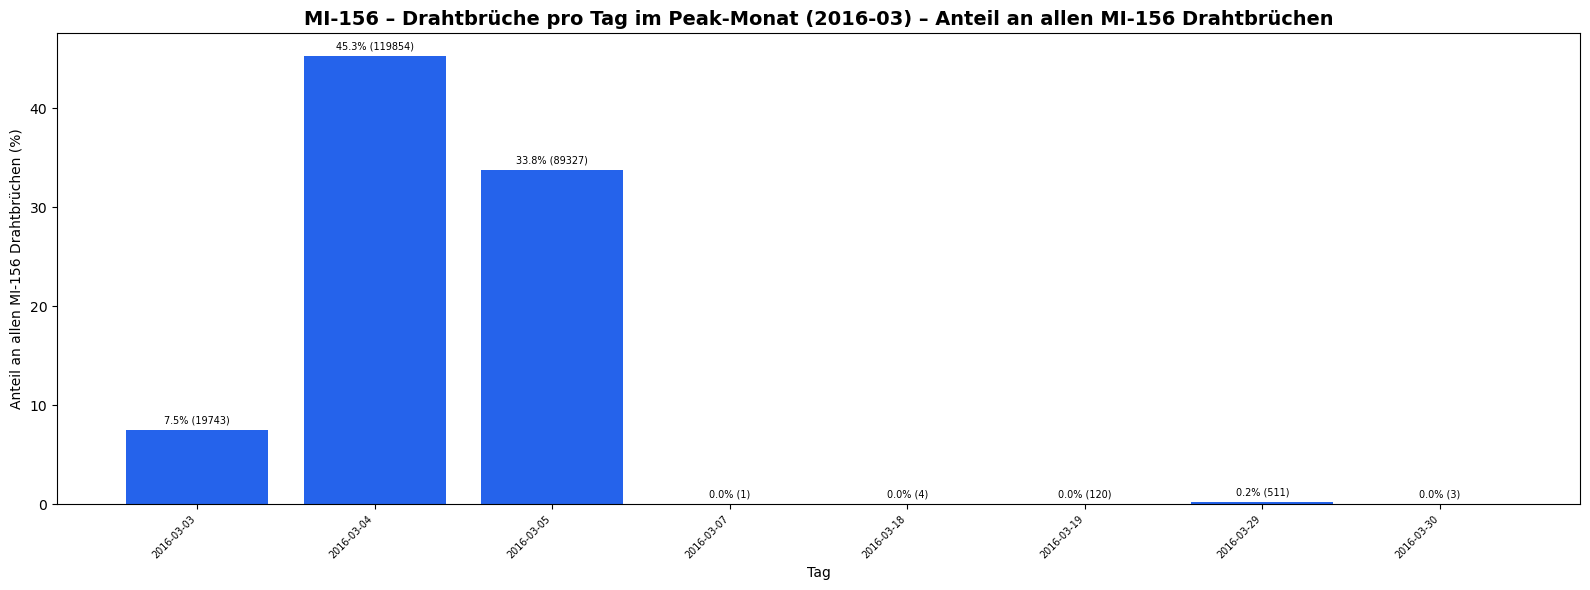

In [10]:
tages_counts = peak_data.groupby(peak_data["Datum"].dt.date).size().sort_index()
tages_pct = (tages_counts / total_mi156 * 100).round(1)

fig, ax = plt.subplots(figsize=(16, 6))
bars = ax.bar(range(len(tages_pct)), tages_pct.values, color="#2563EB")
ax.set_xticks(range(len(tages_pct)))
ax.set_xticklabels([str(d) for d in tages_pct.index], rotation=45, ha="right", fontsize=7)
for i, (val, cnt) in enumerate(zip(tages_pct.values, tages_counts.values, strict=False)):
    ax.text(
        i,
        val + max(tages_pct.values) * 0.01,
        f"{val}% ({cnt})",
        ha="center",
        va="bottom",
        fontsize=7,
    )
ax.set_xlabel("Tag")
ax.set_ylabel("Anteil an allen MI-156 Drahtbrüchen (%)")
ax.set_title(
    f"MI-156 – Drahtbrüche pro Tag im Peak-Monat ({peak_monat}) – Anteil an allen MI-156 Drahtbrüchen",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

In [11]:
mask_peak = (df["Msr"] == "MI-156") & (df["Datum"].dt.to_period("M") == "2016-03")
df_clean = df[~mask_peak].copy()
draht_clean = df_clean[df_clean["Meldung"].str.contains("Drahtbruch", case=False, na=False)].copy()

entfernt = mask_peak.sum()
entfernt_draht = len(draht) - len(draht_clean)

print("=== Peak-Bereinigung: MI-156 März 2016 ===")
print(f"")
print(f"{'Alle Events':.<40} {len(df):>10}")
print(f"{'Entfernte Events':.<40} {entfernt:>10}  ({entfernt / len(df) * 100:.2f}% aller Events)")
print(f"{'Verbleibende Events':.<40} {len(df_clean):>10}  ({len(df_clean) / len(df) * 100:.2f}%)")
print(f"")
print(f"{'Alle Drahtbrüche':.<40} {len(draht):>10}")
print(
    f"{'Entfernte Drahtbrüche':.<40} {entfernt_draht:>10}  ({entfernt_draht / len(draht) * 100:.2f}% aller Drahtbrüche)"
)
print(
    f"{'Verbleibende Drahtbrüche':.<40} {len(draht_clean):>10}  ({len(draht_clean) / len(draht) * 100:.2f}%)"
)
print(f"")
print(f"{'Alle MI-156 Drahtbrüche':.<40} {total_mi156:>10}")
print(
    f"{'Entfernte MI-156 Drahtbrüche':.<40} {entfernt_draht:>10}  ({entfernt_draht / total_mi156 * 100:.2f}% von MI-156)"
)

=== Peak-Bereinigung: MI-156 März 2016 ===

Alle Events.............................    1054556
Entfernte Events........................     229919  (21.80% aller Events)
Verbleibende Events.....................     824637  (78.20%)

Alle Drahtbrüche........................     387041
Entfernte Drahtbrüche...................     229563  (59.31% aller Drahtbrüche)
Verbleibende Drahtbrüche................     157478  (40.69%)

Alle MI-156 Drahtbrüche.................     264668
Entfernte MI-156 Drahtbrüche............     229563  (86.74% von MI-156)


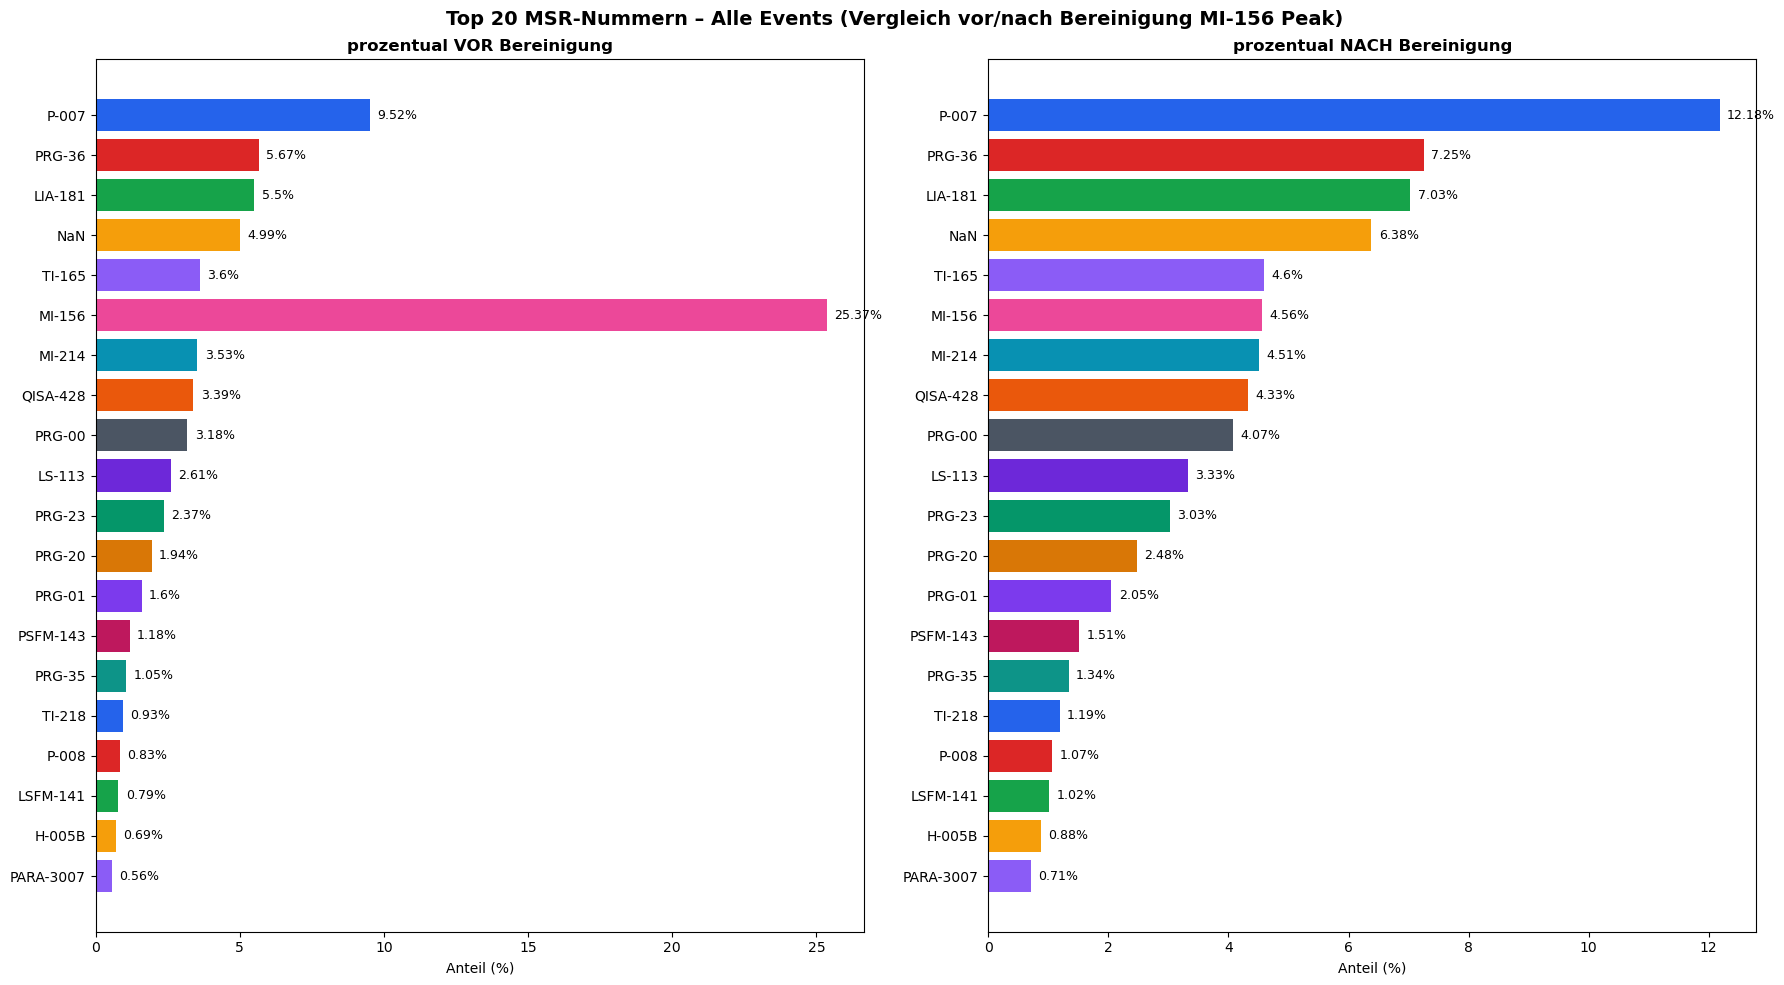

In [12]:
msr_counts_clean = df_clean["Msr"].fillna("NaN").value_counts().head(20)
msr_colors_c = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(msr_counts_clean.index)}

msr_counts_vorher = df["Msr"].fillna("NaN").value_counts()
total_vorher = len(df)
total_nachher = len(df_clean)

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

vorher_pct = (
    msr_counts_vorher.reindex(msr_counts_clean.index, fill_value=0) / total_vorher * 100
).round(2)
bars = axes[0].barh(
    vorher_pct.index, vorher_pct.values, color=[msr_colors_c[m] for m in vorher_pct.index]
)
for bar, val in zip(bars, vorher_pct.values, strict=False):
    axes[0].text(
        bar.get_width() + max(vorher_pct.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[0].set_xlabel("Anteil (%)")
axes[0].set_title("prozentual VOR Bereinigung", fontsize=12, fontweight="bold")
axes[0].invert_yaxis()

nachher_pct = (msr_counts_clean / total_nachher * 100).round(2)
bars2 = axes[1].barh(
    nachher_pct.index, nachher_pct.values, color=[msr_colors_c[m] for m in nachher_pct.index]
)
for bar, val in zip(bars2, nachher_pct.values, strict=False):
    axes[1].text(
        bar.get_width() + max(nachher_pct.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil (%)")
axes[1].set_title("prozentual NACH Bereinigung", fontsize=12, fontweight="bold")
axes[1].invert_yaxis()

plt.suptitle(
    "Top 20 MSR-Nummern – Alle Events (Vergleich vor/nach Bereinigung MI-156 Peak)",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

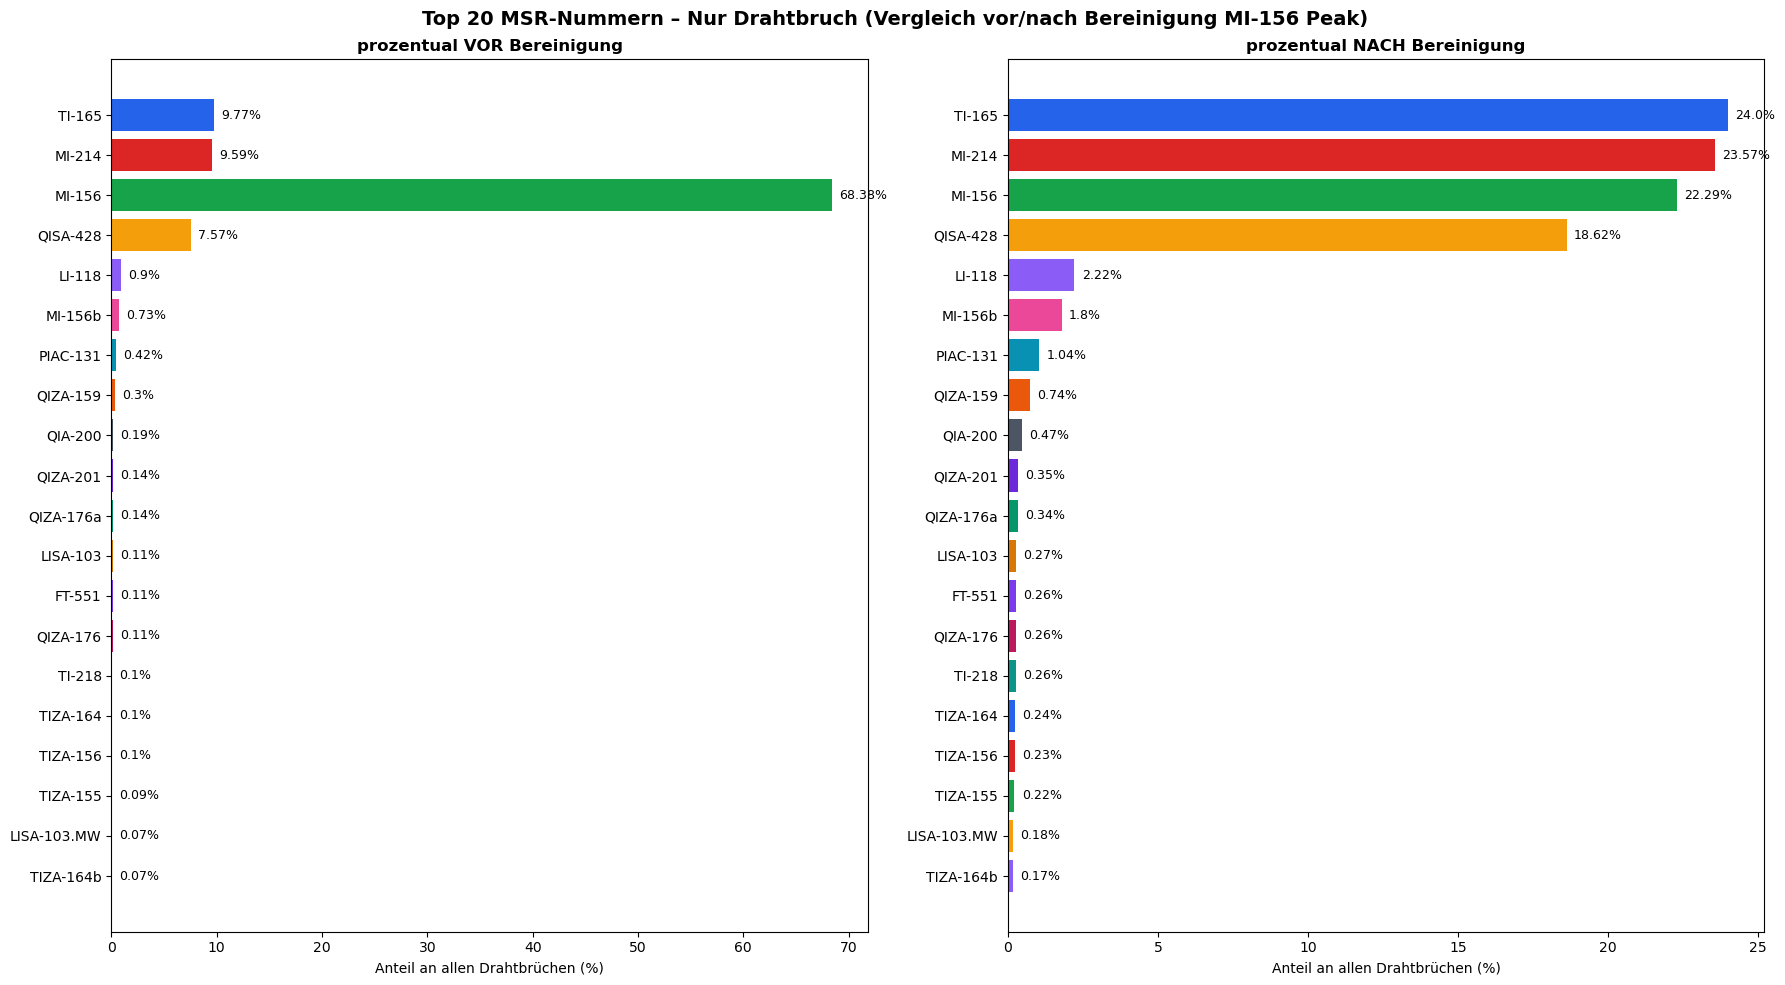

In [13]:
draht_msr_clean = draht_clean["Msr"].fillna("NaN").value_counts().head(20)
draht_msr_colors_c = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(draht_msr_clean.index)}

draht_msr_vorher = draht["Msr"].fillna("NaN").value_counts()
total_draht_vorher = len(draht)
total_draht_nachher = len(draht_clean)

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

vorher_pct_d = (
    draht_msr_vorher.reindex(draht_msr_clean.index, fill_value=0) / total_draht_vorher * 100
).round(2)
bars = axes[0].barh(
    vorher_pct_d.index,
    vorher_pct_d.values,
    color=[draht_msr_colors_c[m] for m in vorher_pct_d.index],
)
for bar, val in zip(bars, vorher_pct_d.values, strict=False):
    axes[0].text(
        bar.get_width() + max(vorher_pct_d.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[0].set_xlabel("Anteil an allen Drahtbrüchen (%)")
axes[0].set_title("prozentual VOR Bereinigung", fontsize=12, fontweight="bold")
axes[0].invert_yaxis()

nachher_pct_d = (draht_msr_clean / total_draht_nachher * 100).round(2)
bars2 = axes[1].barh(
    nachher_pct_d.index,
    nachher_pct_d.values,
    color=[draht_msr_colors_c[m] for m in nachher_pct_d.index],
)
for bar, val in zip(bars2, nachher_pct_d.values, strict=False):
    axes[1].text(
        bar.get_width() + max(nachher_pct_d.values) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val}%",
        va="center",
        fontsize=9,
    )
axes[1].set_xlabel("Anteil an allen Drahtbrüchen (%)")
axes[1].set_title("prozentual NACH Bereinigung", fontsize=12, fontweight="bold")
axes[1].invert_yaxis()

plt.suptitle(
    "Top 20 MSR-Nummern – Nur Drahtbruch (Vergleich vor/nach Bereinigung MI-156 Peak)",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

Top 4 MSR nach Bereinigung: ['TI-165', 'MI-214', 'MI-156', 'QISA-428']
  TI-165: 37801 Events (24.0%)
  MI-214: 37122 Events (23.6%)
  MI-156: 35105 Events (22.3%)
  QISA-428: 29316 Events (18.6%)


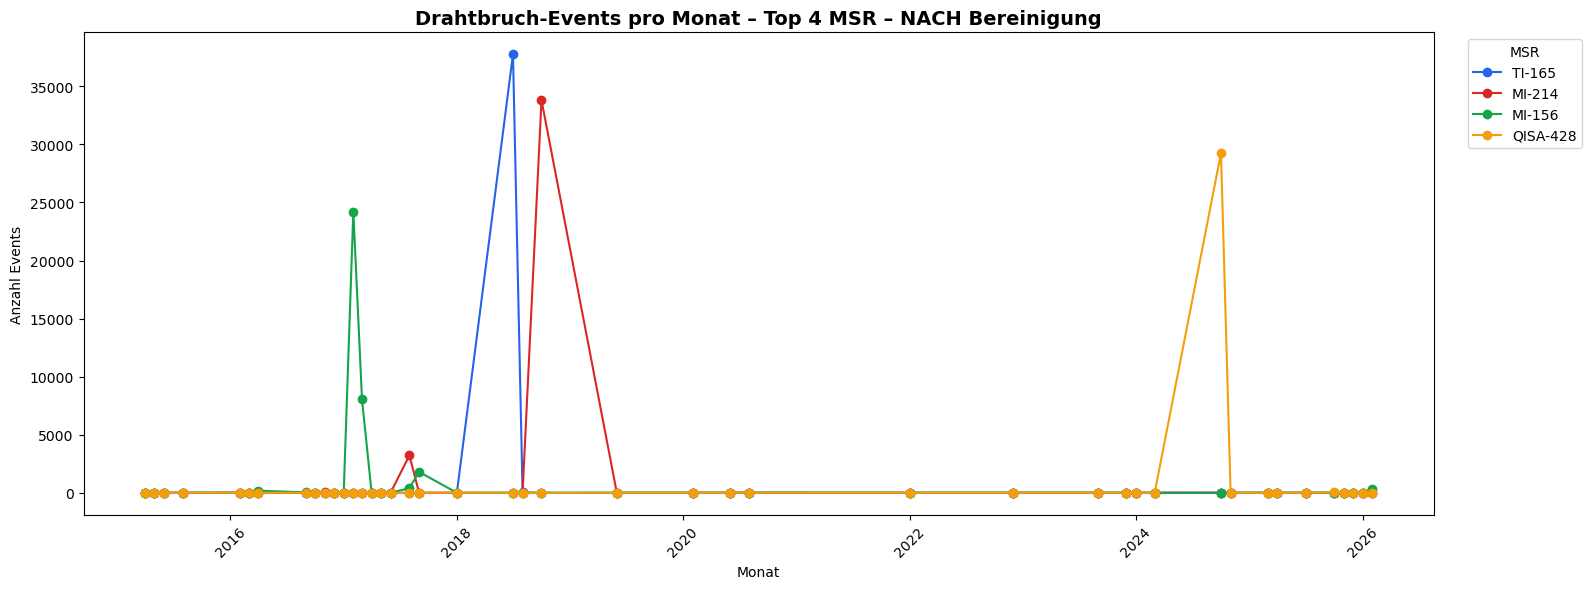

In [14]:
top4_c = draht_clean["Msr"].value_counts().head(4).index.tolist()
draht_top4_c = draht_clean[draht_clean["Msr"].isin(top4_c)].copy()
draht_top4_c["Monat"] = draht_top4_c["Datum"].dt.to_period("M")
draht_top4_c["Stunde"] = draht_top4_c["Datum"].dt.hour
msr_colors_c_top4 = {msr: PALETTE[i] for i, msr in enumerate(top4_c)}

print(f"Top 4 MSR nach Bereinigung: {top4_c}")
for msr in top4_c:
    cnt = len(draht_top4_c[draht_top4_c["Msr"] == msr])
    print(f"  {msr}: {cnt} Events ({cnt / len(draht_clean) * 100:.1f}%)")

# %% Zelle 15: Zeitverlauf – NACH Bereinigung
fig, ax = plt.subplots(figsize=(16, 6))
pivot = draht_top4_c.groupby(["Monat", "Msr"]).size().unstack(fill_value=0)
pivot.index = pivot.index.to_timestamp()
for msr in top4_c:
    if msr in pivot.columns:
        ax.plot(pivot.index, pivot[msr], marker="o", label=msr, color=msr_colors_c_top4[msr])
ax.set_title(
    "Drahtbruch-Events pro Monat – Top 4 MSR – NACH Bereinigung", fontsize=14, fontweight="bold"
)
ax.set_xlabel("Monat")
ax.set_ylabel("Anzahl Events")
ax.legend(title="MSR", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

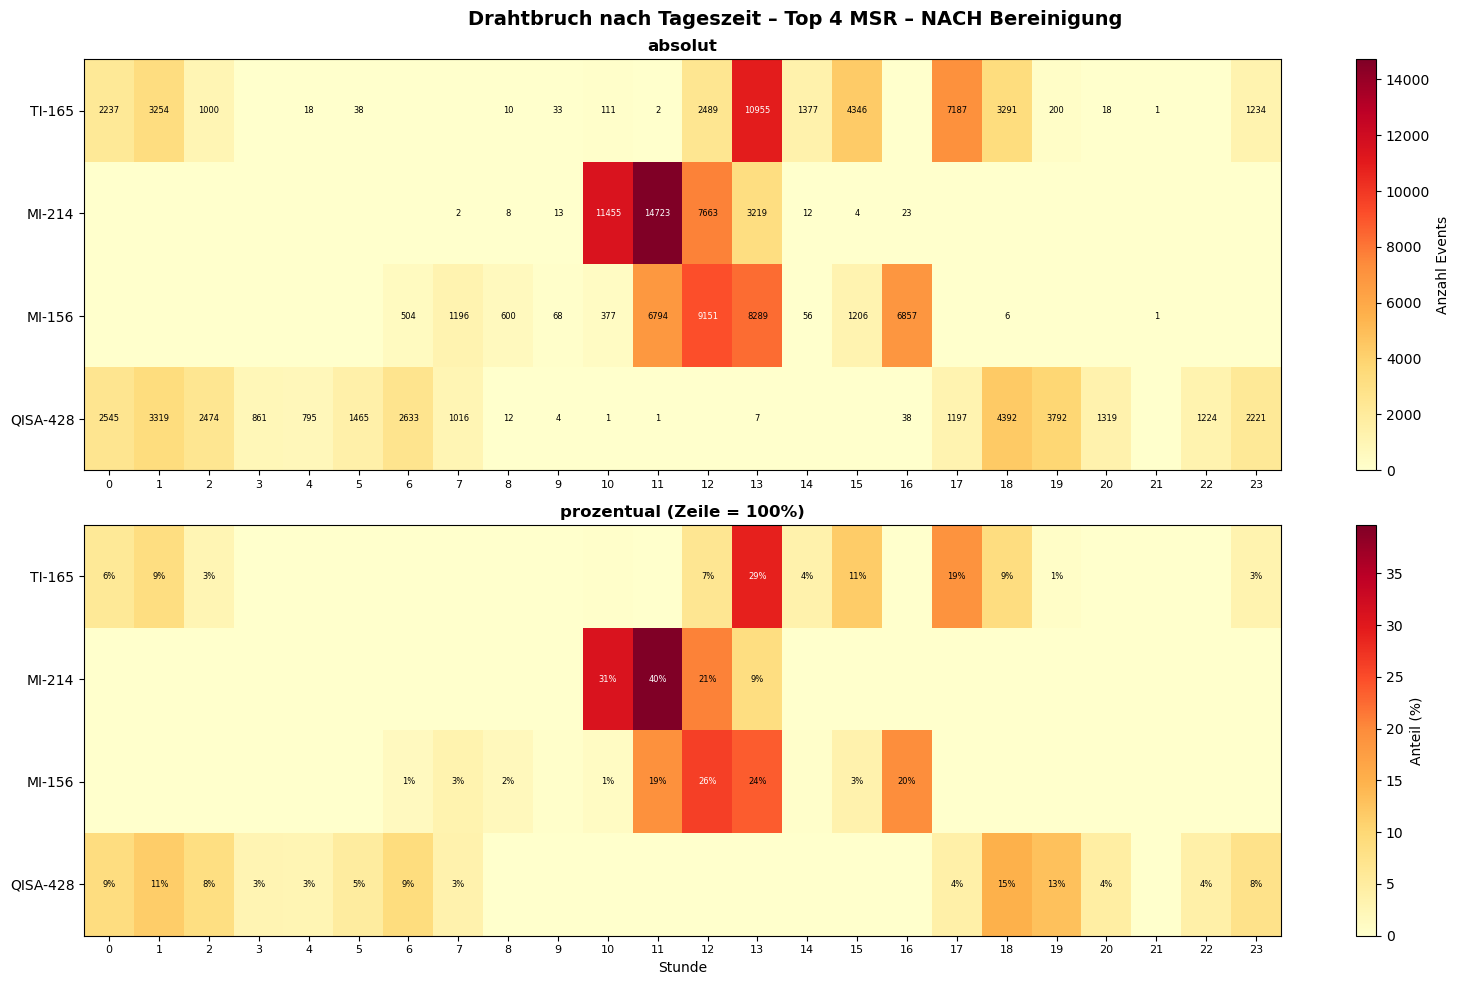

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

ct_stunde = pd.crosstab(draht_top4_c["Msr"], draht_top4_c["Stunde"])
ct_stunde = ct_stunde.reindex(columns=range(24), fill_value=0).loc[top4_c]

im1 = axes[0].imshow(ct_stunde.values, cmap="YlOrRd", aspect="auto")
axes[0].set_yticks(range(len(top4_c)))
axes[0].set_yticklabels(top4_c, fontsize=10)
axes[0].set_xticks(range(24))
axes[0].set_xticklabels(range(24), fontsize=8)
for i in range(len(top4_c)):
    for j in range(24):
        val = ct_stunde.iloc[i, j]
        if val > 0:
            color = "white" if val > ct_stunde.values.max() * 0.6 else "black"
            axes[0].text(j, i, str(val), ha="center", va="center", fontsize=6, color=color)
plt.colorbar(im1, ax=axes[0], label="Anzahl Events")
axes[0].set_title("absolut", fontsize=12, fontweight="bold")

ct_norm = ct_stunde.div(ct_stunde.sum(axis=1), axis=0) * 100
im2 = axes[1].imshow(ct_norm.values, cmap="YlOrRd", aspect="auto")
axes[1].set_yticks(range(len(top4_c)))
axes[1].set_yticklabels(top4_c, fontsize=10)
axes[1].set_xticks(range(24))
axes[1].set_xticklabels(range(24), fontsize=8)
axes[1].set_xlabel("Stunde")
for i in range(len(top4_c)):
    for j in range(24):
        val = ct_norm.iloc[i, j]
        if val >= 0.5:
            color = "white" if val > ct_norm.values.max() * 0.6 else "black"
            axes[1].text(j, i, f"{val:.0f}%", ha="center", va="center", fontsize=6, color=color)
plt.colorbar(im2, ax=axes[1], label="Anteil (%)")
axes[1].set_title("prozentual (Zeile = 100%)", fontsize=12, fontweight="bold")

plt.suptitle(
    "Drahtbruch nach Tageszeit – Top 4 MSR – NACH Bereinigung", fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

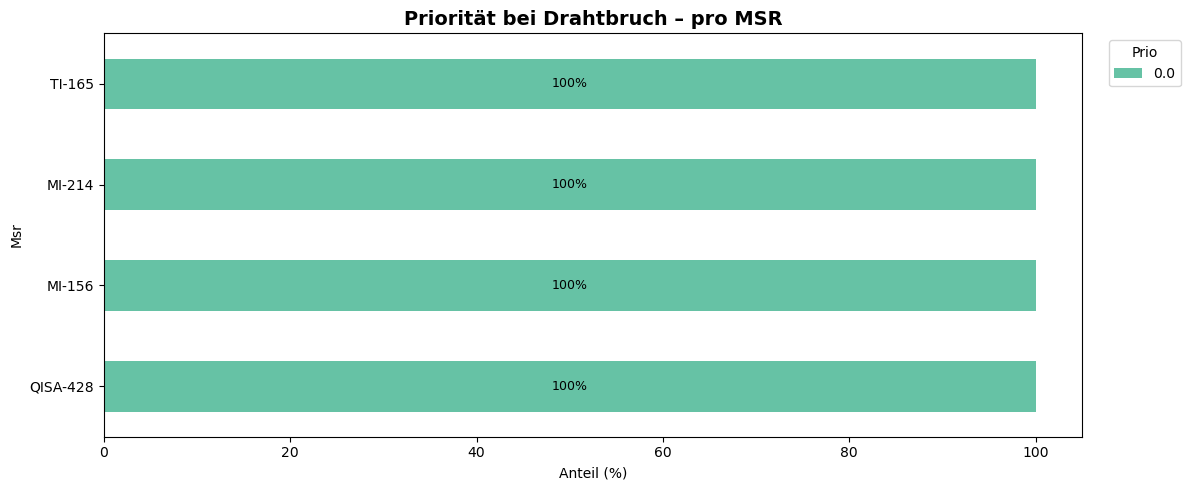

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
ct_prio = pd.crosstab(draht_top4_c["Msr"], draht_top4_c["Prio"].fillna("NaN"))
ct_prio.columns = [str(c) for c in ct_prio.columns]
ct_norm_p = ct_prio.div(ct_prio.sum(axis=1), axis=0) * 100
ct_norm_p.loc[top4_c].plot(kind="barh", stacked=True, ax=ax, colormap="Set2")
for container in ax.containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    ax.bar_label(container, labels=lbl, label_type="center", fontsize=9)
ax.set_xlabel("Anteil (%)")
ax.set_title("Priorität bei Drahtbruch – pro MSR", fontsize=14, fontweight="bold")
ax.legend(title="Prio", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

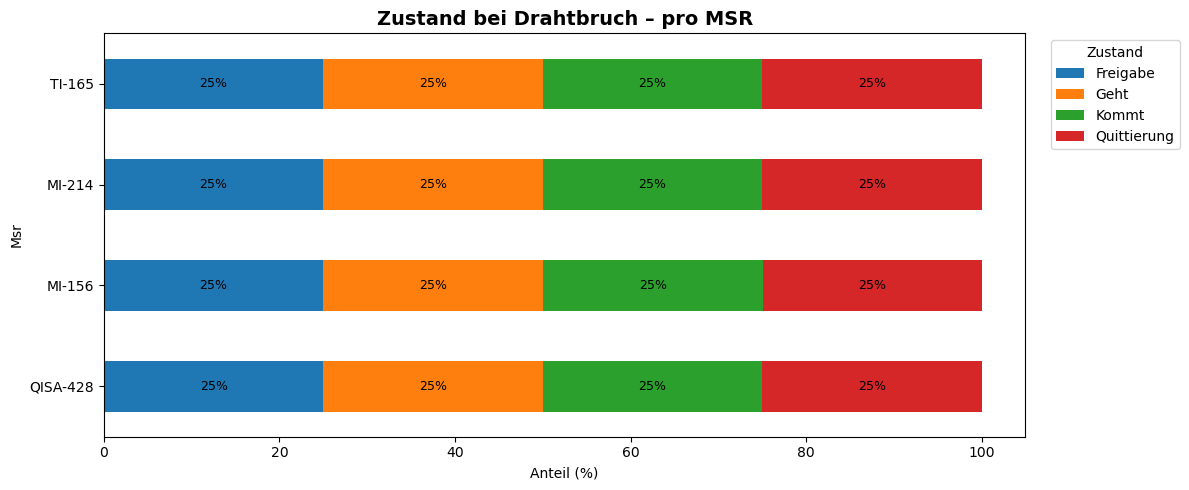

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
ct_zustand = pd.crosstab(draht_top4_c["Msr"], draht_top4_c["Zustand"].fillna("NaN"))
ct_norm_z = ct_zustand.div(ct_zustand.sum(axis=1), axis=0) * 100
ct_norm_z.loc[top4_c].plot(kind="barh", stacked=True, ax=ax)
for container in ax.containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    ax.bar_label(container, labels=lbl, label_type="center", fontsize=9)
ax.set_xlabel("Anteil (%)")
ax.set_title("Zustand bei Drahtbruch – pro MSR", fontsize=14, fontweight="bold")
ax.legend(title="Zustand", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

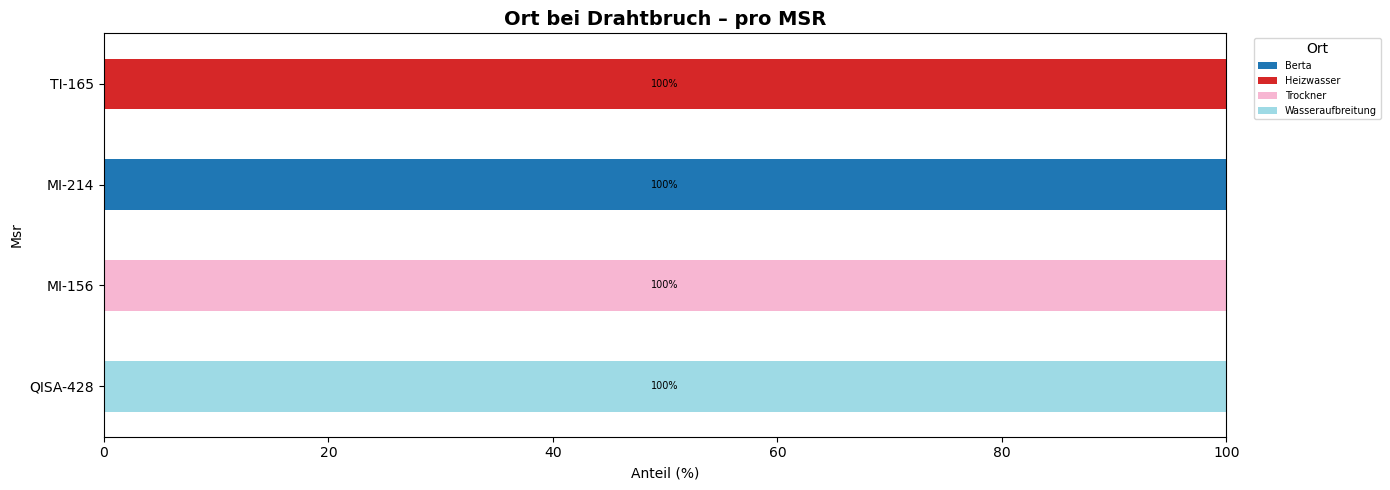

In [18]:
fig, ax = plt.subplots(figsize=(14, 5))
ct_ort = pd.crosstab(draht_top4_c["Msr"], draht_top4_c["Ort"].fillna("NaN"))
ct_norm_o = ct_ort.div(ct_ort.sum(axis=1), axis=0) * 100
ct_norm_o.loc[top4_c].plot(kind="barh", stacked=True, ax=ax, colormap="tab20")
for container in ax.containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    ax.bar_label(container, labels=lbl, label_type="center", fontsize=7)
ax.set_xlabel("Anteil (%)")
ax.set_title("Ort bei Drahtbruch – pro MSR", fontsize=14, fontweight="bold")
ax.legend(title="Ort", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

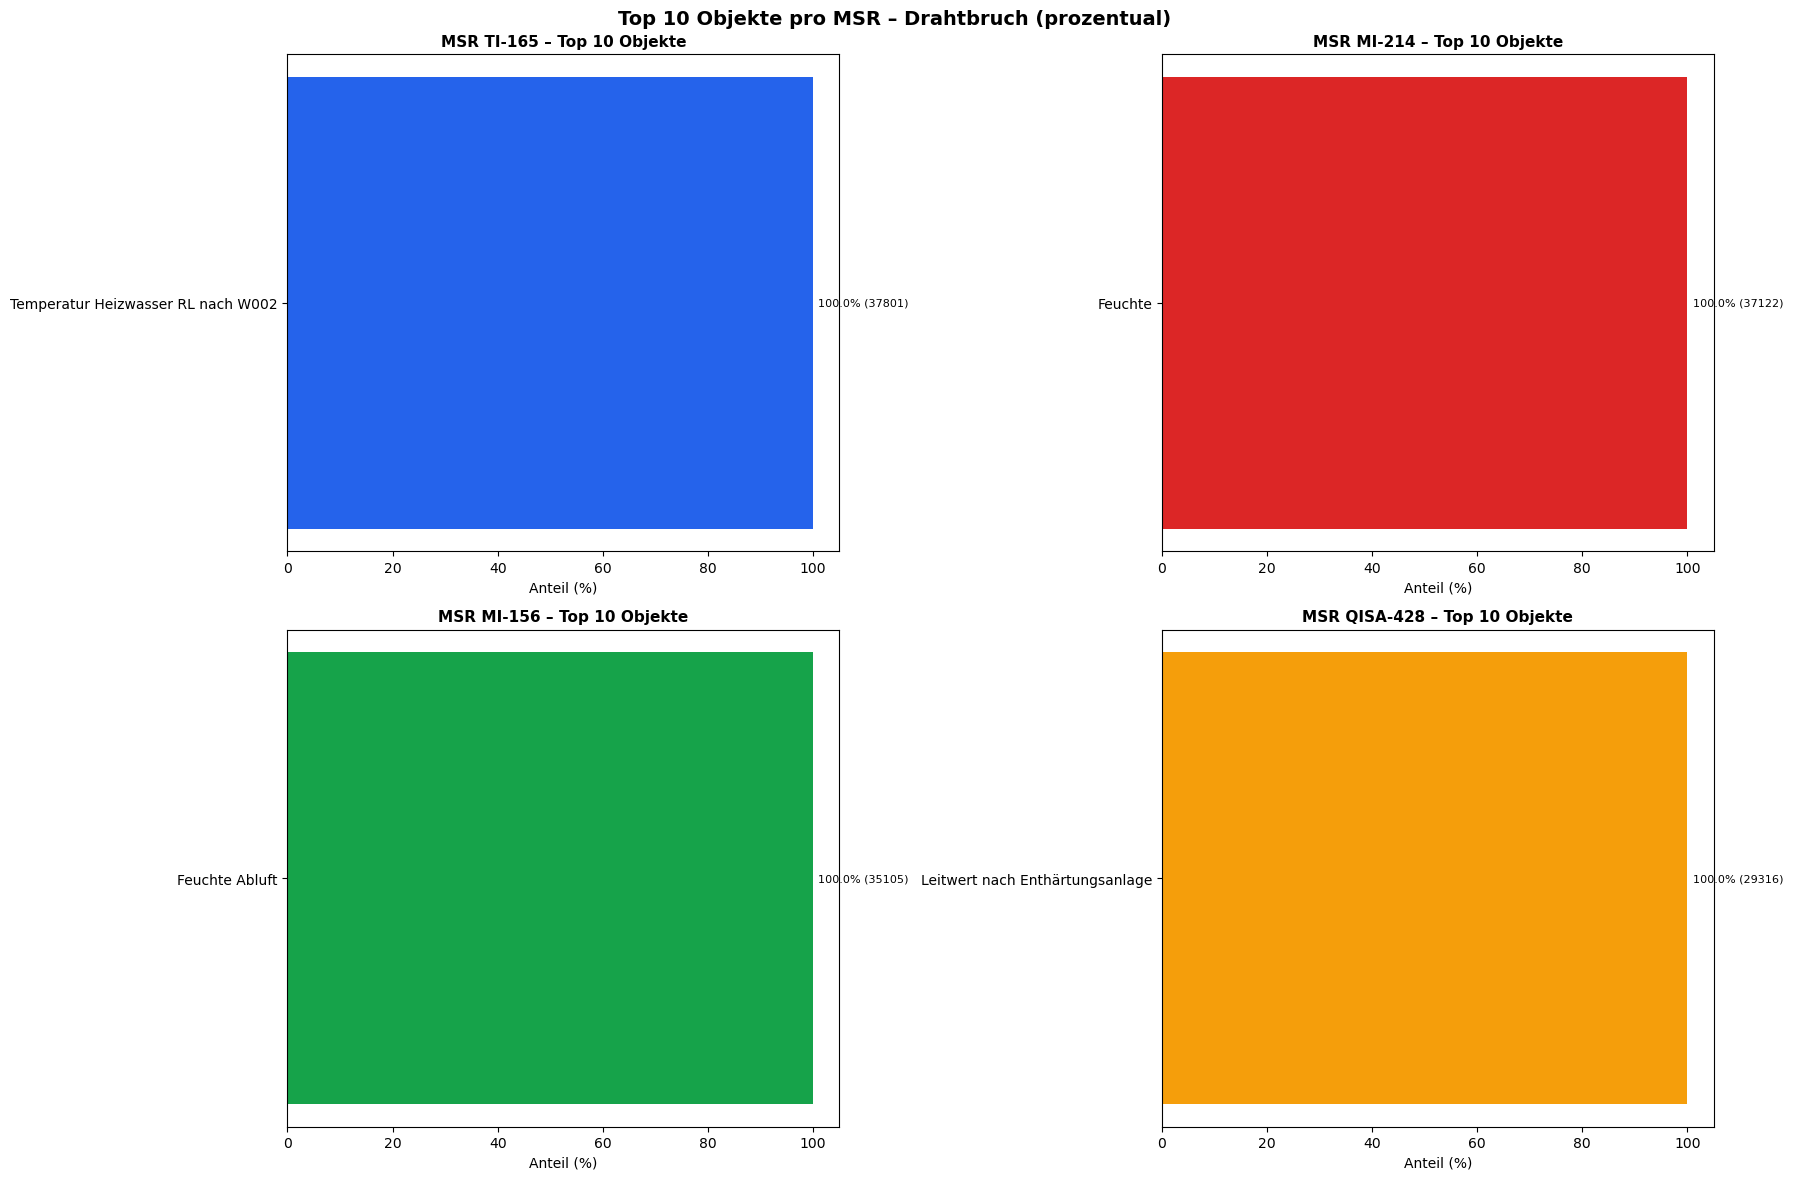

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes_flat = axes.flatten()
for i, msr in enumerate(top4_c):
    sub = draht_top4_c[draht_top4_c["Msr"] == msr]
    obj_counts = sub["Objekt"].value_counts().head(10)
    obj_pct = (obj_counts / len(sub) * 100).round(1)
    bars = axes_flat[i].barh(obj_pct.index, obj_pct.values, color=msr_colors_c_top4[msr])
    for bar, val, cnt in zip(bars, obj_pct.values, obj_counts.values, strict=False):
        axes_flat[i].text(
            bar.get_width() + max(obj_pct.values) * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{val}% ({cnt})",
            va="center",
            fontsize=8,
        )
    axes_flat[i].set_title(f"MSR {msr} – Top 10 Objekte", fontsize=11, fontweight="bold")
    axes_flat[i].set_xlabel("Anteil (%)")
    axes_flat[i].invert_yaxis()
plt.suptitle("Top 10 Objekte pro MSR – Drahtbruch (prozentual)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

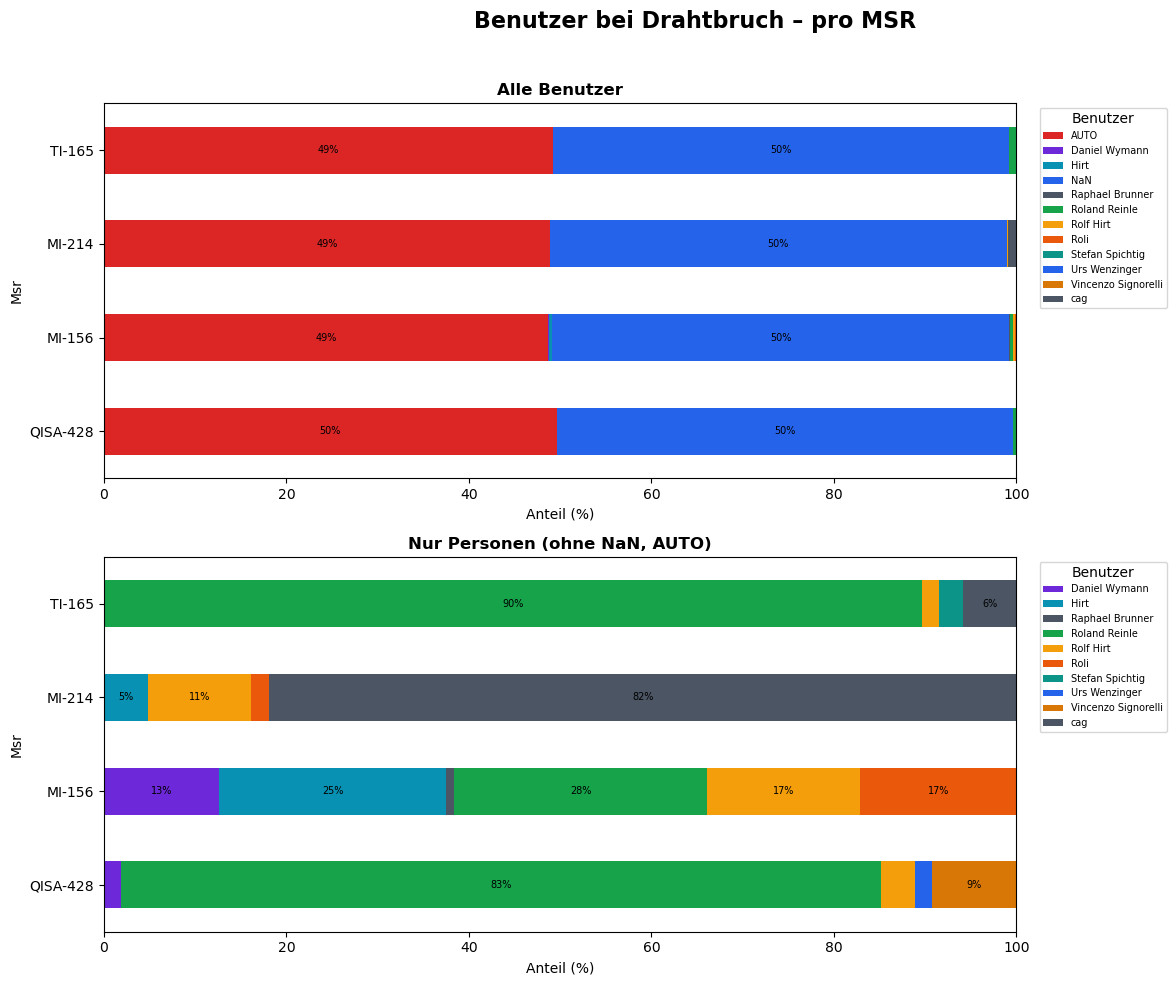

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

ct_user = pd.crosstab(draht_top4_c["Msr"], draht_top4_c["Benutzer"].fillna("NaN"))
ct_norm_u = ct_user.div(ct_user.sum(axis=1), axis=0) * 100
ct_norm_u.loc[top4_c].plot(
    kind="barh",
    stacked=True,
    ax=axes[0],
    color=[user_colors.get(c, "grey") for c in ct_user.columns],
)
for container in axes[0].containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    axes[0].bar_label(container, labels=lbl, label_type="center", fontsize=7)
axes[0].set_xlabel("Anteil (%)")
axes[0].set_title("Alle Benutzer", fontsize=12, fontweight="bold")
axes[0].legend(title="Benutzer", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
axes[0].invert_yaxis()

draht_persons_c = draht_top4_c[
    (draht_top4_c["Benutzer"].notna()) & (~draht_top4_c["Benutzer"].isin(["AUTO"]))
]
ct_user2 = pd.crosstab(draht_persons_c["Msr"], draht_persons_c["Benutzer"])
ct_user2 = ct_user2.reindex(index=[m for m in top4_c if m in ct_user2.index], fill_value=0)
ct_norm_u2 = ct_user2.div(ct_user2.sum(axis=1), axis=0) * 100
ct_norm_u2.plot(
    kind="barh",
    stacked=True,
    ax=axes[1],
    color=[user_colors.get(c, "grey") for c in ct_user2.columns],
)
for container in axes[1].containers:
    lbl = [f"{v.get_width():.0f}%" if v.get_width() > 4 else "" for v in container]
    axes[1].bar_label(container, labels=lbl, label_type="center", fontsize=7)
axes[1].set_xlabel("Anteil (%)")
axes[1].set_title("Nur Personen (ohne NaN, AUTO)", fontsize=12, fontweight="bold")
axes[1].legend(title="Benutzer", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
axes[1].invert_yaxis()

plt.suptitle("Benutzer bei Drahtbruch – pro MSR", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 0.85, 0.96])
plt.show()